<a href="https://colab.research.google.com/github/animeshsahoo5/Image_Classifier/blob/main/Image_Classifier_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Animal Image Classifier Using CNN

**Python + TensorFlow/Keras + OpenCV**

Convolutional Neural Network (CNN) to classify images into six animal categories: **bird, cat, deer, dog, frog, and horse**. It uses the public CIFAR-10 dataset, which can be downloaded directly through Keras.



## 1. Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from google.colab import files
from IPython.display import display
import ipywidgets as widgets
from PIL import Image
import io

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
OpenCV version: 5.0.0
Available GPU: []


## 2. Downloading and prepareing the online dataset
CIFAR-10 has 10 categories. We will only concider six animal categories. (bird, cat, deer, dog, frog, and horse)

In [2]:
# Keras downloads CIFAR-10 automatically the first time this cell runs.
(x_train_all, y_train_all), (x_test_all, y_test_all) = cifar10.load_data()

class_names = ["bird", "cat", "deer", "dog", "frog", "horse"]
cifar_ids = [2, 3, 4, 5, 6, 7]  # CIFAR-10 IDs for the animal categories

def keep_animals(images, labels):
    labels = labels.reshape(-1)
    mask = np.isin(labels, cifar_ids)
    images = images[mask]
    labels = labels[mask]
    # Convert original CIFAR-10 IDs into 0..5 class indexes.
    labels = np.array([cifar_ids.index(int(label)) for label in labels])
    return images, labels

x_train, y_train = keep_animals(x_train_all, y_train_all)
x_test, y_test = keep_animals(x_test_all, y_test_all)

# Pixel values go from 0-255 to 0-1, which helps neural-network training.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Categories:", class_names)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2762s 16us/step
Training images: (30000, 32, 32, 3)
Testing images: (6000, 32, 32, 3)
Categories: ['bird', 'cat', 'deer', 'dog', 'frog', 'horse']


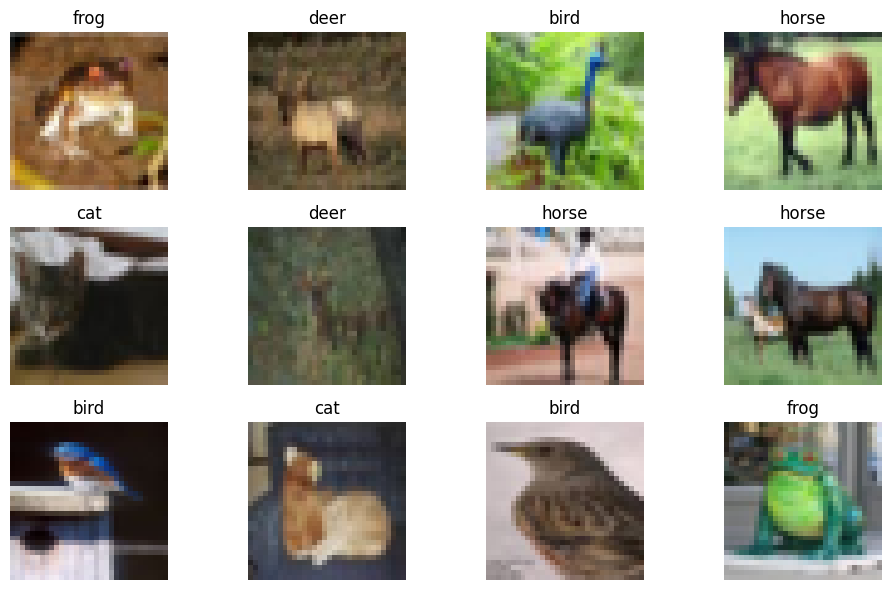

In [11]:
plt.figure(figsize=(10, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Build a simple CNN
Convolution layers learn visual patterns such as edges and shapes.
Pooling layers reduce the image size, and the final dense layer predicts one of the six classes.

In [12]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),#normalization
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 318,918 (1.22 MB)

 Trainable params: 318,918 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model
The number of epochs controls how many times the model sees the training data.

In [14]:
history = model.fit(
    x_train, y_train,
    validation_split=0.4,
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 42s 147ms/step - accuracy: 0.5457 - loss: 1.1914 - val_accuracy: 0.5828 - val_loss: 1.1051
Epoch 2/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 81s 145ms/step - accuracy: 0.5888 - loss: 1.0891 - val_accuracy: 0.6058 - val_loss: 1.0272
Epoch 3/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 44s 155ms/step - accuracy: 0.6276 - loss: 0.9918 - val_accuracy: 0.6105 - val_loss: 1.0431
Epoch 4/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 41s 145ms/step - accuracy: 0.6633 - loss: 0.9119 - val_accuracy: 0.6318 - val_loss: 0.9662
Epoch 5/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 41s 145ms/step - accuracy: 0.6854 - loss: 0.8534 - val_accuracy: 0.6535 - val_loss: 0.9328


## 6. Plot training progress

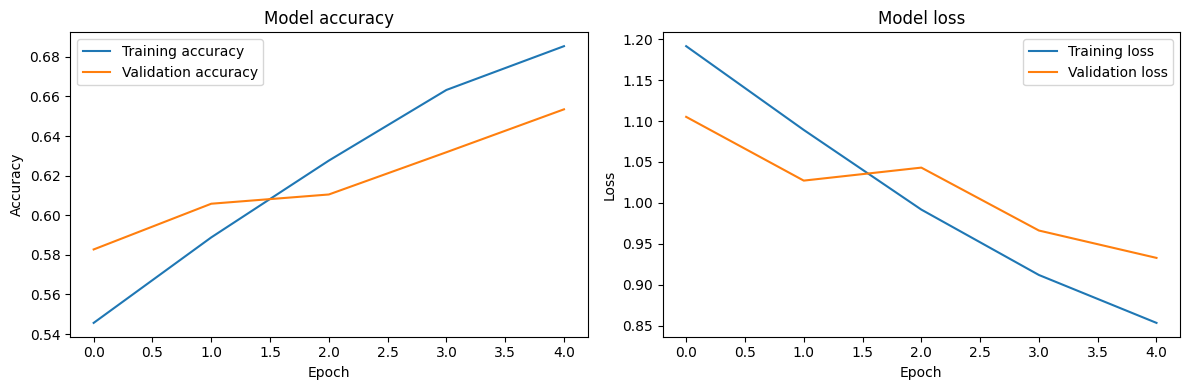

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model loss")
plt.legend()

plt.tight_layout()
plt.show()

## 7. Evaluate on test images

In [16]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 65.83%
Test loss: 0.9392


## 8. Test with sample images from the dataset
These are test-set examples the model did not use during training.

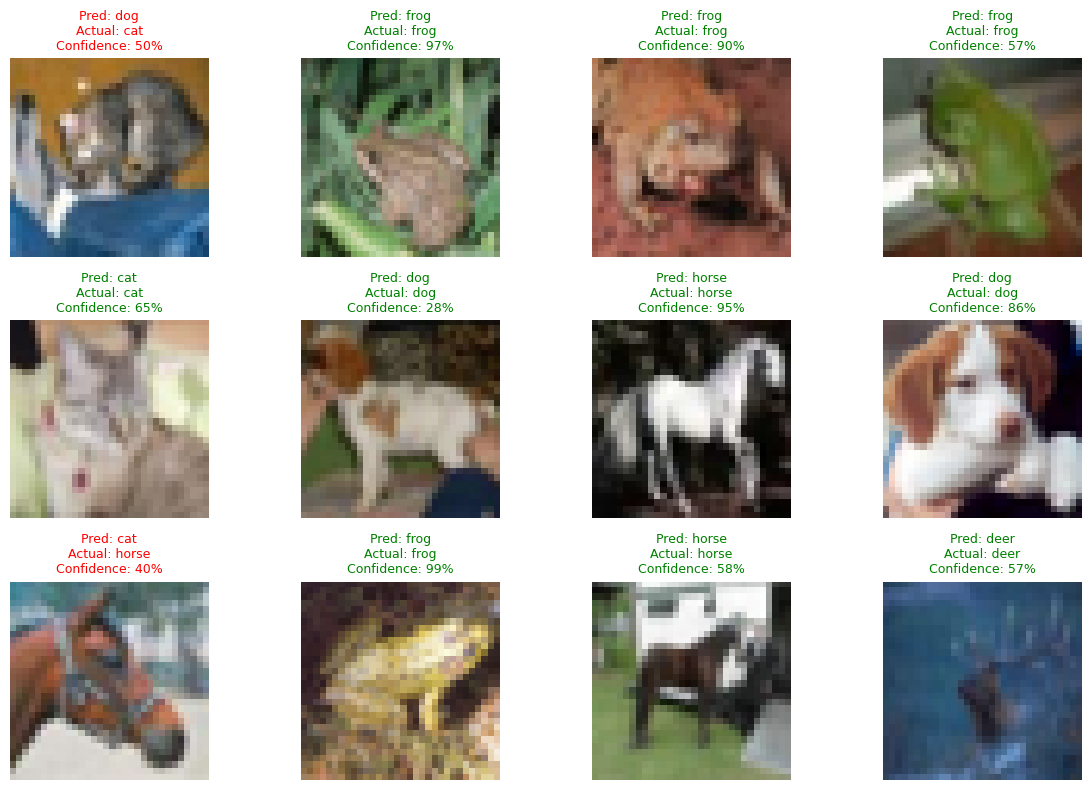

In [17]:
sample_count = 12
sample_images = x_test[:sample_count]
sample_labels = y_test[:sample_count]
sample_probs = model.predict(sample_images, verbose=0)
sample_preds = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(12, 8))
for i in range(sample_count):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i])
    correct = sample_preds[i] == sample_labels[i]
    plt.title(
        f"Pred: {class_names[sample_preds[i]]}\n"
        f"Actual: {class_names[sample_labels[i]]}\n"
        f"Confidence: {sample_probs[i][sample_preds[i]]:.0%}",
        color="green" if correct else "red",
        fontsize=9
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

## 9. Uploading an image and getting a prediction


In [18]:
def predict_uploaded_image(file_bytes):
    # OpenCV decodes the uploaded image from its bytes.
    image_array = np.frombuffer(file_bytes, dtype=np.uint8)
    image_bgr = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

    if image_bgr is None:
        print("Could not read this file. Please upload a valid JPG or PNG.")
        return

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(image_rgb, (32, 32))
    model_input = resized.astype("float32") / 255.0
    model_input = np.expand_dims(model_input, axis=0)

    probabilities = model.predict(model_input, verbose=0)[0]
    best_index = int(np.argmax(probabilities))

    plt.figure(figsize=(4, 4))
    plt.imshow(image_rgb)
    plt.title("Uploaded image")
    plt.axis("off")
    plt.show()

    print(f"Predicted category: {class_names[best_index]}")
    print(f"Confidence: {probabilities[best_index]:.2%}")
    print("\nScores for all categories:")

    plt.figure(figsize=(8, 4))
    plt.bar(class_names, probabilities)
    plt.ylim(0, 1)
    plt.ylabel("Predicted probability")
    plt.title("Model confidence by category")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

upload_button = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Choose an image"
)
predict_button = widgets.Button(
    description="Classify image",
    button_style="success",
    icon="check"
)
output_area = widgets.Output()

def on_predict_clicked(_):
    with output_area:
        output_area.clear_output()
        if not upload_button.value:
            print("Please choose an image first.")
            return

        # ipywidgets versions differ in how uploaded files are stored.
        uploaded_value = upload_button.value
        if isinstance(uploaded_value, dict):
            file_info = next(iter(uploaded_value.values()))
        else:
            file_info = uploaded_value[0]

        file_bytes = file_info["content"]
        if hasattr(file_bytes, "tobytes"):
            file_bytes = file_bytes.tobytes()
        predict_uploaded_image(file_bytes)

predict_button.on_click(on_predict_clicked)
display(widgets.VBox([
    widgets.HTML("<b>Upload an animal image</b>"),
    upload_button,
    predict_button,
    output_area
]))

**10.Saving model**

In [20]:
model.save("animal_cnn_model.keras")
print("Saved model as animal_cnn_model.keras")

Saved model as animal_cnn_model.keras


## Explanation

- **Dataset:** CIFAR-10, filtered to six animal categories.
- **Preprocessing:** pixel normalization from 0–255 to 0–1; uploaded images are resized to 32×32 using OpenCV.
- **Model:** a CNN with convolution, max-pooling, dense, dropout, and softmax layers.
- **Training:** Adam optimizer and sparse categorical cross-entropy loss.
- **Evaluation:** test accuracy and sample predictions on held-out test images.
- **Output:** predicted category, its confidence score, and scores for all six classes.

##Limitation
require a clean background for correct prediction